In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os
import random
import time
import warnings
from datetime import datetime

import torch
from torch.utils.data import DataLoader, Dataset
import torch.nn as nn
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from PIL import Image

warnings.filterwarnings("ignore")

In [4]:
def seed_everything(seed):
    """Mengatur seed untuk reproduktifitas."""
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

seed_everything(42)

In [5]:
hyperparameters = {
    'num_classes': 2,
    'learning_rate': 3e-4,
    'img_size': 224, 
    'batch_size': 32,
    'n_epochs': 30,
    'data_path': r'../../dataset/OralCancer_DatasetGabungan',
}

In [6]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [5]:
def load_data_from_folders(data_path):
    """Memuat path gambar dan label dari struktur folder."""
    image_paths = []
    labels = []
    class_map = {'Cancer': 1, 'Non-Cancer': 0}
    
    for class_name, label in class_map.items():
        class_dir = os.path.join(data_path, class_name)
        if not os.path.isdir(class_dir):
            print(f"Warning: Folder '{class_dir}' tidak ditemukan.")
            continue
        for img_name in os.listdir(class_dir):
            if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                image_paths.append(os.path.join(class_dir, img_name))
                labels.append(label)
                
    return image_paths, labels

all_image_paths, all_labels = load_data_from_folders(hyperparameters['data_path'])

if not all_image_paths:
    raise ValueError("Tidak ada gambar yang ditemukan. Periksa 'data_path' dan struktur folder Anda.")

In [6]:
import collections

# Cek distribusi kelas pada KESELURUHAN DATA SEBELUM oversampling
print("Distribusi KESELURUHAN data SEBELUM oversampling:")
# Variabel yang digunakan adalah 'all_labels'
label_counts_before = collections.Counter(all_labels)
print(f"  - Non-Cancer (0): {label_counts_before[0]} sampel")
print(f"  - Cancer (1): {label_counts_before[1]} sampel")

# Tentukan kelas minoritas dan mayoritas
minority_class_label = 0  # Non-Cancer
majority_class_label = 1  # Cancer

count_majority = label_counts_before[majority_class_label]
count_minority = label_counts_before[minority_class_label]

# Lakukan oversampling jika diperlukan
if count_minority < count_majority:
    num_to_add = count_majority - count_minority
    print(f"\nKelas 'Non-Cancer' adalah minoritas. Menambahkan {num_to_add} sampel ke seluruh dataset...")

    # Dapatkan path dari semua sampel kelas minoritas di seluruh dataset
    # Variabel yang digunakan adalah 'all_image_paths' dan 'all_labels'
    minority_paths = [path for path, label in zip(all_image_paths, all_labels) if label == minority_class_label]
    
    # Duplikasi sampel minoritas
    oversampled_paths_to_add = random.choices(minority_paths, k=num_to_add)
    oversampled_labels_to_add = [minority_class_label] * num_to_add

    # Tambahkan sampel duplikat ke list data utama
    # Variabel yang diubah adalah 'all_image_paths' dan 'all_labels'
    all_image_paths.extend(oversampled_paths_to_add)
    all_labels.extend(oversampled_labels_to_add)

    # Kocok kembali keseluruhan data agar terdistribusi acak
    temp_combined = list(zip(all_image_paths, all_labels))
    random.shuffle(temp_combined)
    all_image_paths, all_labels = zip(*temp_combined)
    
    # Konversi kembali ke list
    all_image_paths = list(all_image_paths)
    all_labels = list(all_labels)

    # Cek distribusi kelas SETELAH oversampling
    print("\nDistribusi KESELURUHAN data SETELAH oversampling:")
    label_counts_after = collections.Counter(all_labels)
    print(f"  - Non-Cancer (0): {label_counts_after[0]} sampel")
    print(f"  - Cancer (1): {label_counts_after[1]} sampel")
    print(f"Total data baru: {len(all_image_paths)} sampel\n")

Distribusi KESELURUHAN data SEBELUM oversampling:
  - Non-Cancer (0): 700 sampel
  - Cancer (1): 990 sampel

Kelas 'Non-Cancer' adalah minoritas. Menambahkan 290 sampel ke seluruh dataset...

Distribusi KESELURUHAN data SETELAH oversampling:
  - Non-Cancer (0): 990 sampel
  - Cancer (1): 990 sampel
Total data baru: 1980 sampel



In [7]:
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_image_paths, all_labels, test_size=0.2, random_state=42, stratify=all_labels
)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.25, random_state=42, stratify=temp_labels
)

print(f"Total gambar: {len(all_image_paths)}")
print(f"Data Latih: {len(train_paths)} sampel")
print(f"Data Validasi: {len(val_paths)} sampel")
print(f"Data Uji: {len(test_paths)} sampel")

Total gambar: 1980
Data Latih: 1584 sampel
Data Validasi: 297 sampel
Data Uji: 99 sampel


In [8]:
class OralCancerDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        
        try:
            image = Image.open(img_path).convert("RGB")
            if self.transform:
                image = self.transform(image)
        except Exception as e:
            print(f"Gagal memuat atau mentransformasi gambar: {img_path}. Error: {e}")
            # Mengembalikan tensor kosong jika terjadi kesalahan
            return torch.zeros((3, hyperparameters['img_size'], hyperparameters['img_size'])), label

        return image, label

In [9]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(hyperparameters['img_size'], scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=20, translate=(0.1, 0.1), scale=(0.9, 1.1), shear=10),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.5, scale=(0.02, 0.25), ratio=(0.3, 3.3), value=0)
])

val_test_transform = transforms.Compose([
    transforms.Resize((hyperparameters['img_size'], hyperparameters['img_size'])),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [10]:
train_dataset = OralCancerDataset(train_paths, train_labels, transform=train_transform)
val_dataset = OralCancerDataset(val_paths, val_labels, transform=val_test_transform)
test_dataset = OralCancerDataset(test_paths, test_labels, transform=val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=hyperparameters['batch_size'], shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=hyperparameters['batch_size'], shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=hyperparameters['batch_size'], shuffle=False)

print(f'Ukuran Train loader: {len(train_loader)}')
print(f'Ukuran Validation loader: {len(val_loader)}')
print(f'Ukuran Test loader: {len(test_loader)}')

Ukuran Train loader: 50
Ukuran Validation loader: 10
Ukuran Test loader: 4


In [11]:
# Di dalam sel [10]
model = models.resnet50(pretrained=True)

for param in model.parameters():
    param.requires_grad = False

for param in model.layer4.parameters():
    param.requires_grad = True

num_ftrs = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(0.5), # Pertahankan Dropout yang kuat
    nn.Linear(num_ftrs, hyperparameters['num_classes'])
)

model = model.to(device)

In [12]:
# Ganti seluruh sel [11] dengan ini

# 1. Gunakan Label Smoothing untuk mencegah overconfidence
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

# 2. Optimizer dengan weight decay yang lebih kuat
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=hyperparameters['learning_rate'],
    weight_decay=1e-3 # Naikkan weight decay secara signifikan
)

# 3. Ganti scheduler dengan CosineAnnealingLR
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=hyperparameters['n_epochs'], # Jumlah epoch total
    eta_min=1e-6 # Nilai LR terendah di akhir
)

In [13]:
def train_and_validate_model(model, train_loader, val_loader, criterion, optimizer, scheduler, hyperparameters, patience=7):
    total_start_time = time.time()
    best_val_loss = float('inf')
    patience_counter = 0

    base_folder = "../../models"
    checkpoint_folder = os.path.join(base_folder, "checkpoints")
    os.makedirs(checkpoint_folder, exist_ok=True)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(hyperparameters['n_epochs']):
        epoch_start_time = time.time()
        
        # Training Phase
        model.train()
        total_train_loss, total_train_correct = 0.0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item() * inputs.size(0)
            total_train_correct += (outputs.argmax(1) == labels).sum().item()

        avg_train_loss = total_train_loss / len(train_loader.dataset)
        train_accuracy = total_train_correct / len(train_loader.dataset) * 100
        history['train_loss'].append(avg_train_loss)
        history['train_acc'].append(train_accuracy)

        # Validation Phase
        model.eval()
        total_val_loss, total_val_correct = 0.0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                total_val_loss += loss.item() * inputs.size(0)
                total_val_correct += (outputs.argmax(1) == labels).sum().item()

        avg_val_loss = total_val_loss / len(val_loader.dataset)
        val_accuracy = total_val_correct / len(val_loader.dataset) * 100
        history['val_loss'].append(avg_val_loss)
        history['val_acc'].append(val_accuracy)

        scheduler.step()
        epoch_time = time.time() - epoch_start_time
        
        print(f'Epoch {epoch + 1}/{hyperparameters["n_epochs"]} | '
              f'Train Loss: {avg_train_loss:.4f}, Acc: {train_accuracy:.2f}% | '
              f'Val Loss: {avg_val_loss:.4f}, Acc: {val_accuracy:.2f}% | '
              f'Time: {epoch_time:.2f}s')

        # Saving the best model
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            patience_counter = 0
            timestamp = datetime.now().strftime("%Y%m%d")
            best_model_path = os.path.join(checkpoint_folder, f'ResNet50_best_model_{timestamp}.pth')
            torch.save(model.state_dict(), best_model_path)
            print(f"Validation loss improved. Saving model to {best_model_path}")
        else:
            patience_counter += 1
            print(f'No improvement. Patience: {patience_counter}/{patience}')

        if patience_counter >= patience:
            print("Early stopping triggered.")
            break

    total_training_time = time.time() - total_start_time
    print(f'Total Training Time: {total_training_time / 60:.2f} minutes')
    return history

In [14]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

In [15]:
def evaluate_model(model, test_loader):
    """Evaluasi model pada test set."""
    model.eval()
    all_preds = []
    all_labels = []
    test_correct = 0
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            test_correct += (preds == labels).sum().item()
    
    test_accuracy = test_correct / len(test_loader.dataset) * 100
    print(f"Test Accuracy: {test_accuracy:.2f}%")
    
    return all_preds, all_labels, test_accuracy

In [16]:
def plot_confusion_matrix(y_true, y_pred, class_names):
    """Plot confusion matrix dengan matplotlib."""
    cm = confusion_matrix(y_true, y_pred)
    
    fig, ax = plt.subplots(figsize=(8, 6))
    
    # Membuat heatmap manual
    im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
    ax.figure.colorbar(im, ax=ax)
    
    # Set ticks
    ax.set(xticks=np.arange(cm.shape[1]),
           yticks=np.arange(cm.shape[0]),
           xticklabels=class_names,
           yticklabels=class_names,
           title='Confusion Matrix',
           ylabel='True Label',
           xlabel='Predicted Label')
    
    # Rotate tick labels
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    
    # Menambahkan text annotations
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
    thresh = cm.max() / 2.
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f'{cm[i, j]}\n({cm_normalized[i, j]:.1f}%)',
                   ha="center", va="center",
                   color="white" if cm[i, j] > thresh else "black",
                   fontsize=12)
    
    plt.tight_layout()
    plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    return cm

In [17]:
def calculate_metrics(y_true, y_pred, class_names):
    """Menghitung dan menampilkan berbagai metrik evaluasi."""
    cm = confusion_matrix(y_true, y_pred)
    
    # Menghitung metrik per kelas
    tn, fp, fn, tp = cm.ravel()
    
    # Metrik untuk kelas positif (Cancer)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0  # Recall/Sensitivity
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    f1_score = 2 * (precision * sensitivity) / (precision + sensitivity) if (precision + sensitivity) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    print("\n" + "="*50)
    print("HASIL EVALUASI MODEL")
    print("="*50)
    
    print(f"\nOverall Accuracy: {accuracy*100:.2f}%")
    print(f"\nUntuk Kelas 'Cancer' (Positive Class):")
    print(f"  - Sensitivity (Recall): {sensitivity*100:.2f}%")
    print(f"  - Specificity: {specificity*100:.2f}%")
    print(f"  - Precision: {precision*100:.2f}%")
    print(f"  - F1-Score: {f1_score*100:.2f}%")
    
    print(f"\nConfusion Matrix Details:")
    print(f"  - True Positives (Cancer detected correctly): {tp}")
    print(f"  - True Negatives (Non-Cancer detected correctly): {tn}")
    print(f"  - False Positives (Non-Cancer misclassified as Cancer): {fp}")
    print(f"  - False Negatives (Cancer misclassified as Non-Cancer): {fn}")
    
    # Classification report
    print("\n" + "="*50)
    print("CLASSIFICATION REPORT")
    print("="*50)
    print(classification_report(y_true, y_pred, target_names=class_names))
    
    return {
        'accuracy': accuracy,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'precision': precision,
        'f1_score': f1_score,
        'confusion_matrix': cm
    }

In [18]:
def visualize_predictions(model, test_dataset, num_samples=8):
    """Visualisasi beberapa sampel prediksi."""
    model.eval()
    class_names = ['Non-Cancer', 'Cancer']
    
    # Ambil sampel random
    indices = random.sample(range(len(test_dataset)), min(num_samples, len(test_dataset)))
    
    fig, axes = plt.subplots(2, 4, figsize=(15, 8))
    axes = axes.ravel()
    
    with torch.no_grad():
        for idx, i in enumerate(indices):
            if idx >= len(axes):
                break
                
            image, true_label = test_dataset[i]
            image_display = image.clone()
            
            # Denormalisasi untuk display
            mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
            std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
            image_display = image_display * std + mean
            image_display = torch.clamp(image_display, 0, 1)
            
            # Prediksi
            image = image.unsqueeze(0).to(device)
            output = model(image)
            probabilities = torch.nn.functional.softmax(output, dim=1)
            _, pred = torch.max(output, 1)
            
            # Plot
            axes[idx].imshow(image_display.permute(1, 2, 0))
            axes[idx].axis('off')
            
            true_class = class_names[true_label]
            pred_class = class_names[pred.item()]
            prob = probabilities[0][pred.item()].item() * 100
            
            color = 'green' if true_label == pred.item() else 'red'
            axes[idx].set_title(f'True: {true_class}\nPred: {pred_class} ({prob:.1f}%)', 
                               color=color, fontsize=10)
    
    plt.tight_layout()
    plt.savefig('sample_predictions.png', dpi=300, bbox_inches='tight')
    plt.show()

Epoch 1/30 | Train Loss: 0.4559, Acc: 83.71% | Val Loss: 0.3803, Acc: 89.56% | Time: 39.93s
Validation loss improved. Saving model to ./OralCancer_Models\Checkpoints\ResNet50_best_model_20250707.pth
Epoch 2/30 | Train Loss: 0.3465, Acc: 91.67% | Val Loss: 0.3528, Acc: 93.60% | Time: 39.18s
Validation loss improved. Saving model to ./OralCancer_Models\Checkpoints\ResNet50_best_model_20250707.pth
Epoch 3/30 | Train Loss: 0.3142, Acc: 93.81% | Val Loss: 0.2908, Acc: 94.95% | Time: 43.16s
Validation loss improved. Saving model to ./OralCancer_Models\Checkpoints\ResNet50_best_model_20250707.pth
Epoch 4/30 | Train Loss: 0.2938, Acc: 94.76% | Val Loss: 0.3270, Acc: 94.61% | Time: 45.13s
No improvement. Patience: 1/7
Epoch 5/30 | Train Loss: 0.2798, Acc: 95.90% | Val Loss: 0.2834, Acc: 95.29% | Time: 45.02s
Validation loss improved. Saving model to ./OralCancer_Models\Checkpoints\ResNet50_best_model_20250707.pth
Epoch 6/30 | Train Loss: 0.2876, Acc: 95.39% | Val Loss: 0.2827, Acc: 94.95% | Tim

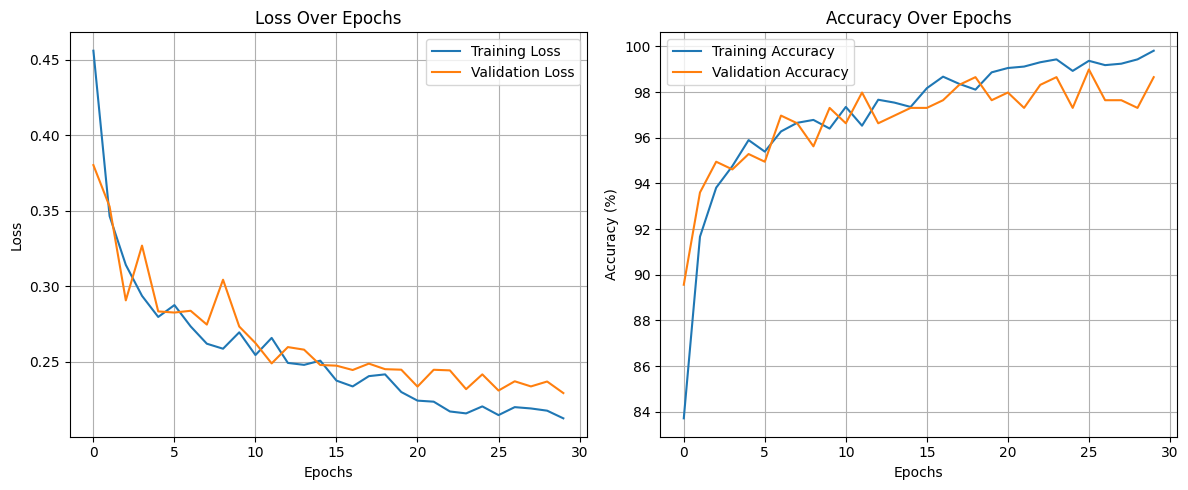


EVALUASI MODEL PADA TEST SET
Test Accuracy: 100.00%


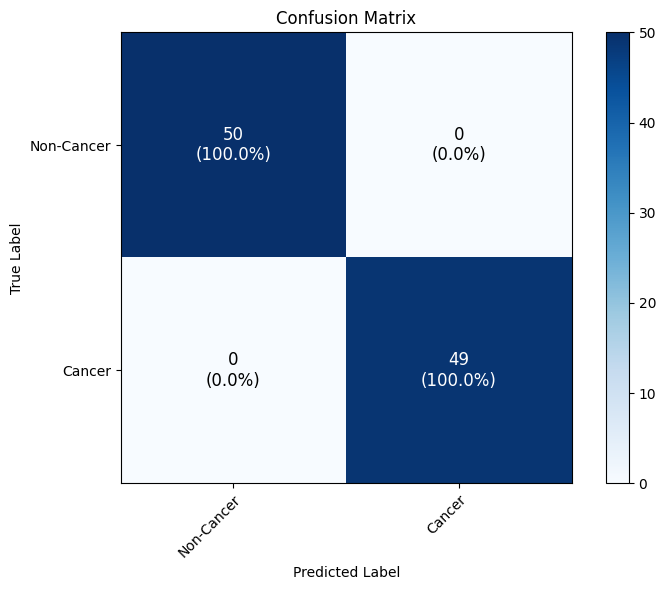


HASIL EVALUASI MODEL

Overall Accuracy: 100.00%

Untuk Kelas 'Cancer' (Positive Class):
  - Sensitivity (Recall): 100.00%
  - Specificity: 100.00%
  - Precision: 100.00%
  - F1-Score: 100.00%

Confusion Matrix Details:
  - True Positives (Cancer detected correctly): 49
  - True Negatives (Non-Cancer detected correctly): 50
  - False Positives (Non-Cancer misclassified as Cancer): 0
  - False Negatives (Cancer misclassified as Non-Cancer): 0

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Non-Cancer       1.00      1.00      1.00        50
      Cancer       1.00      1.00      1.00        49

    accuracy                           1.00        99
   macro avg       1.00      1.00      1.00        99
weighted avg       1.00      1.00      1.00        99


Membuat visualisasi sampel prediksi...


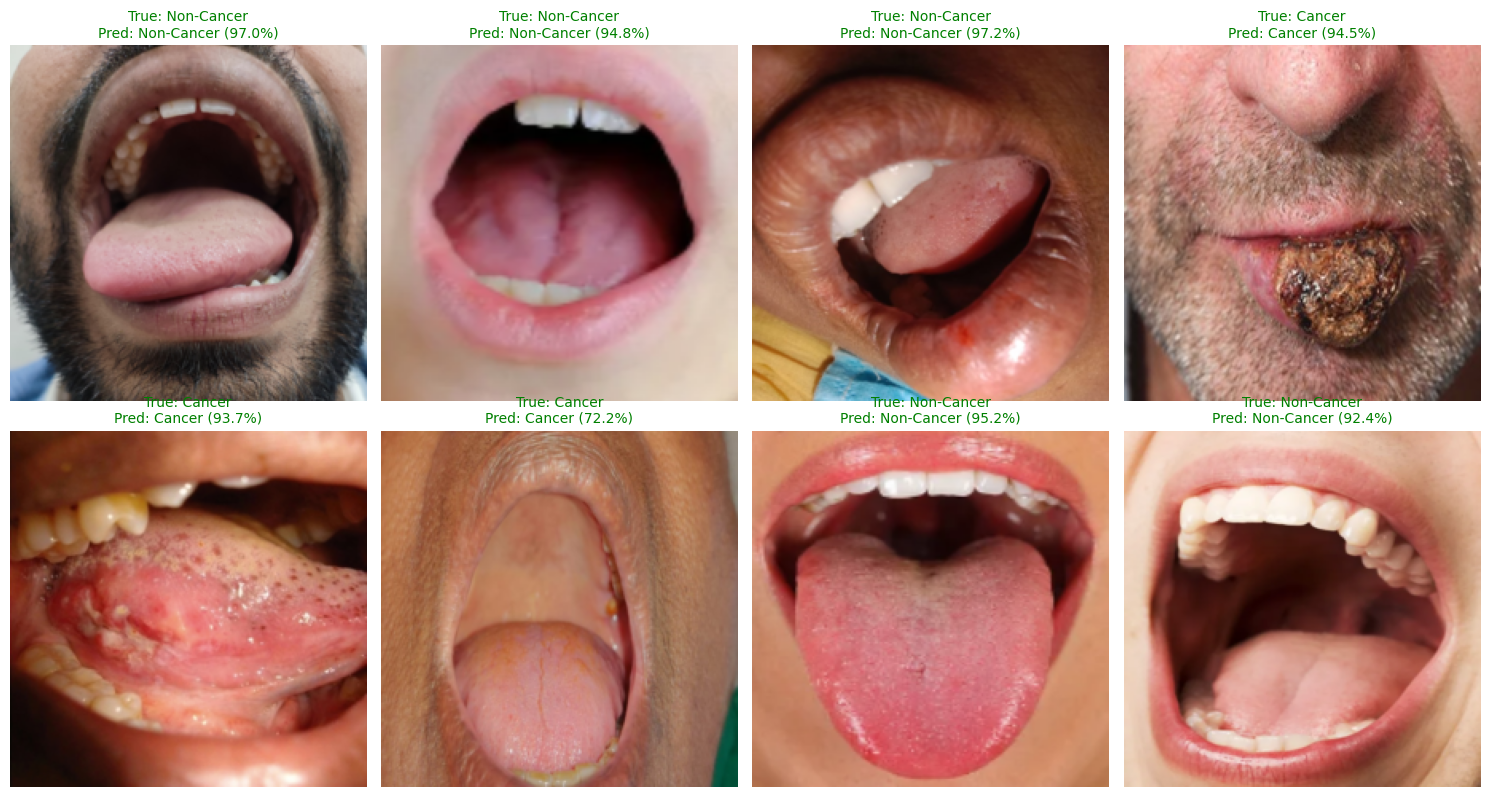


Hasil evaluasi telah disimpan ke 'evaluation_results.txt'


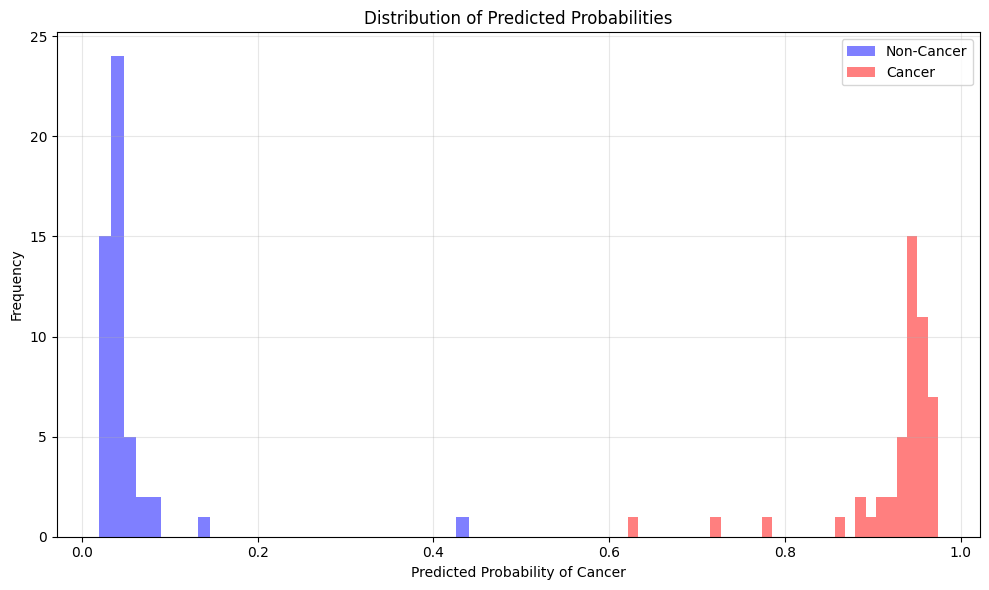


Analisis selesai! File yang dihasilkan:
1. confusion_matrix.png - Confusion matrix dengan persentase
2. sample_predictions.png - Visualisasi sampel prediksi
3. probability_distribution.png - Distribusi probabilitas prediksi
4. evaluation_results.txt - Ringkasan hasil evaluasi
5. training_history_plot.png - Grafik loss dan accuracy selama training


In [19]:
if __name__ == '__main__':
    training_history = train_and_validate_model(
        model, train_loader, val_loader, criterion, optimizer, scheduler, hyperparameters
    )

    # Plotting training history
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(training_history['train_loss'], label='Training Loss')
    plt.plot(training_history['val_loss'], label='Validation Loss')
    plt.title('Loss Over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    
    plt.subplot(1, 2, 2)
    plt.plot(training_history['train_acc'], label='Training Accuracy')
    plt.plot(training_history['val_acc'], label='Validation Accuracy')
    plt.title('Accuracy Over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.savefig('training_history_plot.png')
    plt.show()


    print("\n" + "="*50)
    print("EVALUASI MODEL PADA TEST SET")
    print("="*50)
    
    # Evaluasi model
    all_preds, all_labels, test_accuracy = evaluate_model(model, test_loader)
    
    # Nama kelas
    class_names = ['Non-Cancer', 'Cancer']
    
    # Plot confusion matrix
    cm = plot_confusion_matrix(all_labels, all_preds, class_names)
    
    # Hitung dan tampilkan metrik
    metrics = calculate_metrics(all_labels, all_preds, class_names)
    
    # Visualisasi beberapa prediksi
    print("\nMembuat visualisasi sampel prediksi...")
    visualize_predictions(model, test_dataset, num_samples=8)
    
    # Simpan hasil evaluasi ke file
    with open('evaluation_results.txt', 'w') as f:
        f.write("="*50 + "\n")
        f.write("HASIL EVALUASI MODEL ORAL CANCER DETECTION\n")
        f.write(f"Tanggal: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
        f.write("="*50 + "\n\n")
        
        f.write(f"Model: ResNet50 (Fine-tuned)\n")
        f.write(f"Total Test Samples: {len(test_dataset)}\n")
        f.write(f"Overall Accuracy: {metrics['accuracy']*100:.2f}%\n\n")
        
        f.write("Confusion Matrix:\n")
        f.write(f"{cm}\n\n")
        
        f.write("Detailed Metrics:\n")
        f.write(f"Sensitivity (Recall): {metrics['sensitivity']*100:.2f}%\n")
        f.write(f"Specificity: {metrics['specificity']*100:.2f}%\n")
        f.write(f"Precision: {metrics['precision']*100:.2f}%\n")
        f.write(f"F1-Score: {metrics['f1_score']*100:.2f}%\n")
    
    print("\nHasil evaluasi telah disimpan ke 'evaluation_results.txt'")
    
    # Plot distribusi probabilitas prediksi
    plt.figure(figsize=(10, 6))
    
    # Dapatkan probabilitas untuk analisis lebih lanjut
    model.eval()
    cancer_probs = []
    true_labels_list = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            probs = torch.nn.functional.softmax(outputs, dim=1)
            cancer_probs.extend(probs[:, 1].cpu().numpy())  # Probabilitas untuk kelas Cancer
            true_labels_list.extend(labels.numpy())
    
    # Plot distribusi probabilitas
    cancer_probs = np.array(cancer_probs)
    true_labels_array = np.array(true_labels_list)
    
    plt.hist(cancer_probs[true_labels_array == 0], bins=30, alpha=0.5, label='Non-Cancer', color='blue')
    plt.hist(cancer_probs[true_labels_array == 1], bins=30, alpha=0.5, label='Cancer', color='red')
    plt.xlabel('Predicted Probability of Cancer')
    plt.ylabel('Frequency')
    plt.title('Distribution of Predicted Probabilities')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('probability_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("\nAnalisis selesai! File yang dihasilkan:")
    print("1. confusion_matrix.png - Confusion matrix dengan persentase")
    print("2. sample_predictions.png - Visualisasi sampel prediksi")
    print("3. probability_distribution.png - Distribusi probabilitas prediksi")
    print("4. evaluation_results.txt - Ringkasan hasil evaluasi")
    print("5. training_history_plot.png - Grafik loss dan accuracy selama training")